# Интерпретируемая классификация древних письменностей при разном контексте

Продолжение предыдущей работы: **ResNet-18 + анализ фильтров первого сверточного слоя + словарь текстовых признаков + Grad-CAM**.

Новый фактор эксперимента — размер контекста: `N = 1, 2, 3, 5, 8, 16` последовательных символов.

Полный конвейер:

**строка → сегментация → контексты N → нормализация → ResNet-18 → фильтры → словарь → текстовая аргументация → Grad-CAM → метрики.**

Исходные строки сначала делятся на train/validation/test, и только потом сегментируются. Это не допускает утечки между выборками.

В предыдущем отчёте словарь был центральной частью интерпретации: для выбранных фильтров находились изображения с максимальной активацией, после визуального анализа фильтрам сопоставлялись текстовые описания; неинтерпретируемые фильтры исключались.

In [1]:
!pip install datasets huggingface_hub

In [2]:
# 1. Устанавливаем модуль быстрой загрузки
!pip install -q hf_transfer datasets

# 2. Включаем его через переменную окружения
import os
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 49.2 MB/s eta 0:00:0000:0100:01


In [59]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

# Получаем секрет из Kaggle
user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HF_TOKEN")

# Логинимся в Hugging Face
login(token=hf_token)

In [7]:
import random
from huggingface_hub import snapshot_download
from datasets import load_dataset
import os
import shutil

# настройки

dataset1_name = "Fra1sse/segmented_lines_alexandrian_letter"
dataset2_name = "Fra1sse/segmented_lines_volodchina"

class1 = "alexandrian_letter"
class2 = "volodchina_hilarion"

max_per_class = 2500

base_dir = "dataset"

random.seed(42)


# создаём структуру папок

for cls in [class1, class2]:
    os.makedirs(f"{base_dir}/{cls}", exist_ok=True)


# функция сохранения

def save_images(images, folder):

    for i, img in enumerate(images):

        path = os.path.join(folder, f"{i}.png")

        img.save(path)

# загрузка датасетов

# Скачиваем только нужные файлы датасета в локальную папку
dataset1_path = snapshot_download(
    repo_id="Fra1sse/segmented_lines_alexandrian_letter",
    repo_type="dataset",
    local_dir="./hf_cache/alexandrian",
    local_dir_use_symlinks=False, # Важно: чтобы файлы реально копировались
    max_workers=8 # Kaggle обычно позволяет 8+ потоков
)

# Загружаем из уже скачанной папки (или указываем streaming=True, если хотите совсем без ожидания)
dataset1 = load_dataset("imagefolder", data_dir=dataset1_path)

images1 = list(dataset1['train']['image'])
random.shuffle(images1)
images1 = images1[:max_per_class]
print("Класс 1:", len(images1))
save_images(images1, f"{base_dir}/{class1}")




dataset2_path = snapshot_download(
    repo_id="Fra1sse/segmented_lines_volodchina",
    repo_type="dataset",
    local_dir="./hf_cache/volodchina",
    local_dir_use_symlinks=False, # Важно: чтобы файлы реально копировались
    max_workers=8 # Kaggle обычно позволяет 8+ потоков
)

# Загружаем из уже скачанной папки (или указываем streaming=True, если хотите совсем без ожидания)
dataset2 = load_dataset("imagefolder", data_dir=dataset2_path)

images2 = list(dataset2['train']['image'])
random.shuffle(images2)
images2 = images2[:max_per_class]
print("Класс 2:", len(images2))
save_images(images2, f"{base_dir}/{class2}")



print("Датасет готов")

Fetching ... files: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/2670 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Класс 1: 2500


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Fetching ... files: 0it [00:00, ?it/s]

Resolving data files:   0%|          | 0/2942 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Класс 2: 2500
Датасет готов


In [159]:
# 1. НАСТРОЙКИ

from pathlib import Path
import os, json, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import cv2


SOURCE_DIRS = {
    "alexandrian_letter": Path("/kaggle/working/dataset/alexandrian_letter"),
    "vologodchina_hilarion": Path("/kaggle/working/dataset/volodchina_hilarion"),
}

OUTPUT_DIR = Path("/kaggle/working/symbol_context_experiment")

CONTEXT_SIZES = [1, 2, 3, 5, 8, 16]
RUN_CONTEXT_SIZES = CONTEXT_SIZES

MAX_IMAGES_PER_CLASS = 2500
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

SEED = 42
BATCH_SIZE = 16
EPOCHS = 10
LR = 1e-4
NUM_WORKERS = 2

IMAGE_SIZE = 224

# Каноническая высота отдельного символа ДО сборки контекста.
TARGET_SYMBOL_HEIGHT = 96
SYMBOL_GAP = 8

MIN_COMPONENT_AREA = 20
MIN_COMPONENT_HEIGHT = 40
MIN_COMPONENT_WIDTH = 30

TOP_FILTERS_PER_CLASS = 10
TOP_FILTERS_PER_IMAGE = 3
TOP_ACTIVATION_IMAGES_PER_FILTER = 9

ARGUMENTATION_TEST_SAMPLES = None

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Настройки загружены.")

Настройки загружены.


## 2. Импорты и зависимости

В предыдущей работе использовались PyTorch, NumPy и Pillow, а ResNet-18 обучалась с Adam (`lr=0.0001`), batch size 16 и 10 эпохами; эти значения сохранены как базовые.

In [31]:
# Для Colab при необходимости:
# !pip -q install torch torchvision scikit-learn pandas matplotlib pillow opencv-python

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, roc_auc_score, log_loss
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

CLASS_NAMES = sorted(SOURCE_DIRS)
CLASS_TO_ID = {c:i for i,c in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i:c for c,i in CLASS_TO_ID.items()}

print("Device:", DEVICE)
print(CLASS_TO_ID)

Device: cuda
{'alexandrian_letter': 0, 'vologodchina_hilarion': 1}


## 3. Поиск изображений строк

In [32]:
EXTS = {".png",".jpg",".jpeg",".tif",".tiff",".bmp",".webp"}

def collect_images(source_dirs):
    rows = []
    for label, directory in source_dirs.items():
        if not directory.exists():
            raise FileNotFoundError(f"Не найдена папка: {directory}")
        for p in directory.rglob("*"):
            if p.is_file() and p.suffix.lower() in EXTS:
                rows.append({"path":str(p), "label":label})
    return pd.DataFrame(rows)

all_lines = collect_images(SOURCE_DIRS)
print(all_lines.groupby("label").size())
display(all_lines.head())

label
alexandrian_letter       2500
vologodchina_hilarion    2500
dtype: int64


,path,label
0,/kaggle/working/dataset/alexandrian_letter/216...,alexandrian_letter
1,/kaggle/working/dataset/alexandrian_letter/340...,alexandrian_letter
2,/kaggle/working/dataset/alexandrian_letter/240...,alexandrian_letter
3,/kaggle/working/dataset/alexandrian_letter/198...,alexandrian_letter
4,/kaggle/working/dataset/alexandrian_letter/151...,alexandrian_letter


## 4. Разбиение строк до сегментации

Это обязательное правило эксперимента. В старой работе использовалось 70/15/15; здесь сохраняем эту схему. 

In [33]:
def split_lines(df):
    parts = []
    for label, g in df.groupby("label"):
        g = g.sample(frac=1, random_state=SEED).reset_index(drop=True)
        if MAX_IMAGES_PER_CLASS:
            g = g.iloc[:min(MAX_IMAGES_PER_CLASS, len(g))]
        n = len(g)
        a = int(n*TRAIN_RATIO)
        b = a + int(n*VAL_RATIO)
        x = [g.iloc[:a].copy(), g.iloc[a:b].copy(), g.iloc[b:].copy()]
        for d, split in zip(x, ["train","val","test"]):
            d["split"] = split
            parts.append(d)
    out = pd.concat(parts, ignore_index=True)
    assert out.groupby("path")["split"].nunique().max() == 1
    return out.sample(frac=1, random_state=SEED).reset_index(drop=True)

line_splits = split_lines(all_lines)
display(pd.crosstab(line_splits.label, line_splits.split))

split,test,train,val
label,,,
alexandrian_letter,375,1750,375
vologodchina_hilarion,375,1750,375


In [81]:
import gc
import torch

del dataset1, dataset2
del images1, images2


print("Память очищена")

Память очищена


## 5. Сегментация строки на символоподобные компоненты

Используется CV-сегментация: бинаризация → connected components → группировка по вертикальному положению → сортировка слева направо.

Перед обучением обязательно визуально проверить несколько десятков строк. Если компоненты режут символы или объединяют соседние символы, параметры сегментации нужно скорректировать.

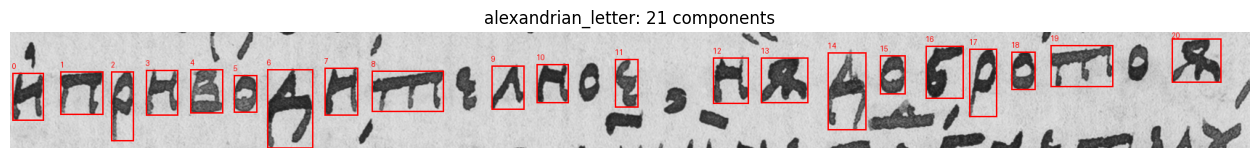

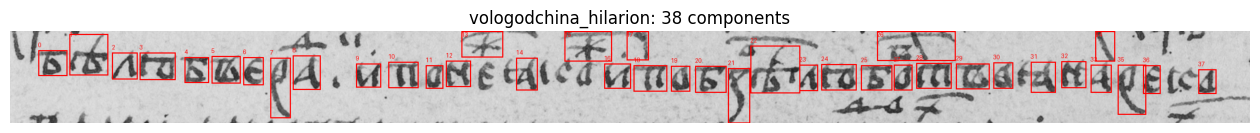

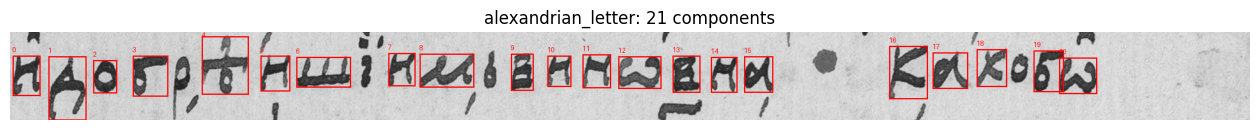

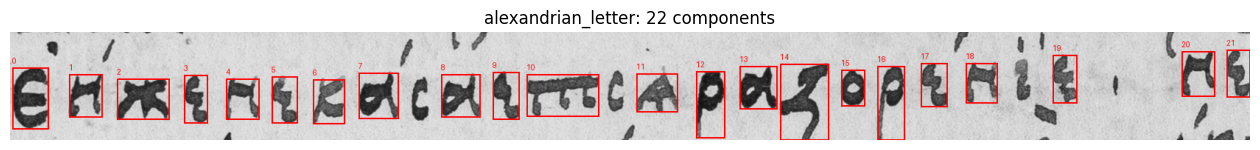

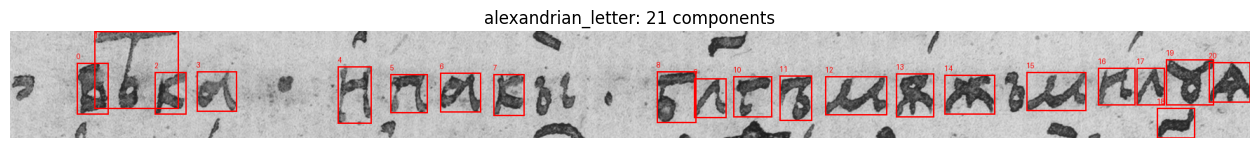

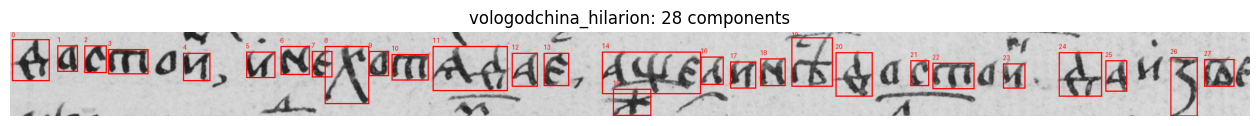

In [34]:
def segment_line(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(path)
    blur = cv2.GaussianBlur(img, (3,3), 0)
    _, bw = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(bw, 8)
    boxes = []
    for i in range(1,n):
        x,y,w,h,area = stats[i]
        if area >= MIN_COMPONENT_AREA and h >= MIN_COMPONENT_HEIGHT and w >= MIN_COMPONENT_WIDTH:
            boxes.append((x,y,w,h,area))
    boxes.sort(key=lambda b:b[0])
    return img, boxes

def show_segmentation(df, n=6):
    for _,r in df.sample(min(n,len(df)), random_state=SEED).iterrows():
        img, boxes = segment_line(r.path)
        vis = Image.fromarray(img).convert("RGB")
        d = ImageDraw.Draw(vis)
        for i,(x,y,w,h,a) in enumerate(boxes):
            d.rectangle((x,y,x+w,y+h), outline="red", width=2)
            d.text((x,max(0,y-15)), str(i), fill="red")
        plt.figure(figsize=(16,3))
        plt.imshow(vis); plt.title(f"{r.label}: {len(boxes)} components"); plt.axis("off"); plt.show()

show_segmentation(line_splits[line_splits.split=="train"])

## 6. Нормализация символа и сборка контекста

Здесь специально не используется простое растягивание каждого готового контекста до 224×224. Сначала каждый компонент приводится к общей высоте `TARGET_SYMBOL_HEIGHT`, с сохранением пропорций, затем символы объединяются.

Это уменьшает масштабный конфаунд: при переходе от `N=1` к `N=16` отдельная графема не должна автоматически становиться меньше только из-за количества символов.

После сборки весь контекст вписывается в 224×224 с padding.

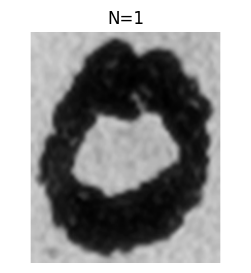

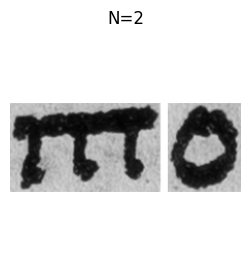

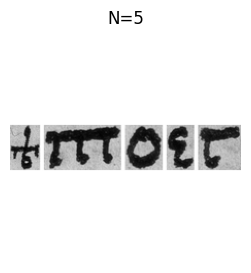

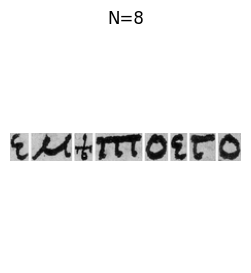

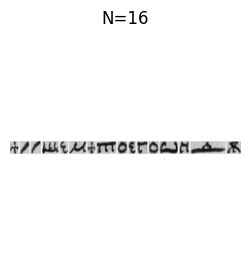

In [38]:
def crop(gray, box, pad=2):
    x,y,w,h,_ = box
    H,W = gray.shape
    return Image.fromarray(gray[max(0,y-pad):min(H,y+h+pad),
                                max(0,x-pad):min(W,x+w+pad)])

def normalize_symbol(im):
    im = im.convert("L")
    w,h = im.size
    nw = max(1, round(w*TARGET_SYMBOL_HEIGHT/max(h,1)))
    return im.resize((nw,TARGET_SYMBOL_HEIGHT), Image.Resampling.LANCZOS)

def compose(symbols):
    width = sum(x.width for x in symbols) + SYMBOL_GAP*(len(symbols)-1)
    out = Image.new("L",(width,TARGET_SYMBOL_HEIGHT),255)
    x = 0
    for s in symbols:
        out.paste(s,(x,0)); x += s.width+SYMBOL_GAP
    return out

def letterbox(im):
    w,h = im.size
    scale = min(IMAGE_SIZE/max(w,1), IMAGE_SIZE/max(h,1))
    nw,nh = max(1,round(w*scale)),max(1,round(h*scale))
    im = im.resize((nw,nh),Image.Resampling.LANCZOS)
    out = Image.new("L",(IMAGE_SIZE,IMAGE_SIZE),255)
    out.paste(im,((IMAGE_SIZE-nw)//2,(IMAGE_SIZE-nh)//2))
    return out

def line_to_contexts(path, n):
    gray, boxes = segment_line(path)
    symbols = [normalize_symbol(crop(gray,b)) for b in boxes]
    out = []
    for start in range(len(symbols)-n+1):
        ctx = letterbox(compose(symbols[start:start+n]))
        out.append((ctx,start,start+n-1))
    return out

p = line_splits.iloc[0].path
for n in [1,2,5,8,16]:
    cs = line_to_contexts(p,n)
    if cs:
        plt.figure(figsize=(4,3)); plt.imshow(cs[len(cs)//2][0],cmap="gray")
        plt.title(f"N={n}"); plt.axis("off"); plt.show()

## 7. Генерация контекстных датасетов

In [36]:
def build_context_dataset(line_df, n):
    root = OUTPUT_DIR/"datasets"/f"context_{n}"
    root.mkdir(parents=True, exist_ok=True)
    rows=[]
    for _,r in line_df.iterrows():
        contexts=line_to_contexts(r.path,n)
        stem=Path(r.path).stem
        for j,(im,a,b) in enumerate(contexts):
            out=root/r.split/r.label/f"{stem}__ctx{n}__{j:05d}.png"
            out.parent.mkdir(parents=True,exist_ok=True)
            im.save(out)
            rows.append({
                "path":str(out),"label":r.label,"split":r.split,
                "source_line":r.path,"context_size":n,
                "start_symbol":a,"end_symbol":b
            })
    meta=pd.DataFrame(rows)
    meta.to_csv(root/"metadata.csv",index=False)
    return meta

context_metadata={}
for n in RUN_CONTEXT_SIZES:
    print("Создание N=",n)
    context_metadata[n]=build_context_dataset(line_splits,n)
    display(context_metadata[n].groupby(["split","label"]).size())

Создание N= 1


split  label                
test   alexandrian_letter        8037
       vologodchina_hilarion    10489
train  alexandrian_letter       37335
       vologodchina_hilarion    49266
val    alexandrian_letter        8033
       vologodchina_hilarion    10579
dtype: int64

Создание N= 2


split  label                
test   alexandrian_letter        7662
       vologodchina_hilarion    10115
train  alexandrian_letter       35585
       vologodchina_hilarion    47516
val    alexandrian_letter        7658
       vologodchina_hilarion    10204
dtype: int64

Создание N= 3


split  label                
test   alexandrian_letter        7287
       vologodchina_hilarion     9741
train  alexandrian_letter       33835
       vologodchina_hilarion    45766
val    alexandrian_letter        7283
       vologodchina_hilarion     9829
dtype: int64

... (2 outputs left out)

Создание N= 8


split  label                
test   alexandrian_letter        5412
       vologodchina_hilarion     7871
train  alexandrian_letter       25090
       vologodchina_hilarion    37016
val    alexandrian_letter        5409
       vologodchina_hilarion     7954
dtype: int64

Создание N= 16


split  label                
test   alexandrian_letter        2422
       vologodchina_hilarion     4879
train  alexandrian_letter       11134
       vologodchina_hilarion    23016
val    alexandrian_letter        2420
       vologodchina_hilarion     4954
dtype: int64

## 8. Dataset, аугментация и ResNet-18

В предыдущей работе аугментация применялась только к train, а validation/test не аугментировались. Использовались шум, небольшие наклоны и изменение контраста.

Горизонтальное отражение здесь намеренно не используется: оно может менять графическую структуру письменности.

In [37]:
train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=3, translate=(.02,.02), scale=(.97,1.03), fill=255),
    transforms.ColorJitter(brightness=.08, contrast=.15),
    transforms.ToTensor(),
    transforms.Normalize([.5],[.5])
])
eval_tf = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize([.5],[.5])
])

class ContextDataset(Dataset):
    def __init__(self,meta,split,tf):
        self.df=meta[meta.split==split].reset_index(drop=True); self.tf=tf
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]
        return self.tf(Image.open(r.path).convert("L")), CLASS_TO_ID[r.label], r.path

def loaders(meta):
    return (
        DataLoader(ContextDataset(meta,"train",train_tf),BATCH_SIZE,True,num_workers=NUM_WORKERS),
        DataLoader(ContextDataset(meta,"val",eval_tf),BATCH_SIZE,False,num_workers=NUM_WORKERS),
        DataLoader(ContextDataset(meta,"test",eval_tf),BATCH_SIZE,False,num_workers=NUM_WORKERS)
    )

def make_model():
    m=models.resnet18(weights=ResNet18_Weights.DEFAULT)
    old=m.conv1
    new=nn.Conv2d(1,64,7,2,3,bias=False)
    with torch.no_grad(): new.weight[:] = old.weight.mean(1,keepdim=True)
    m.conv1=new
    m.fc=nn.Linear(m.fc.in_features,len(CLASS_NAMES))
    return m

## 9. Обучение, тестирование и сохранение моделей

Все функции ниже вызываются в едином цикле эксперимента.

In [72]:
def epoch(model,loader,criterion,opt=None):
    model.train(opt is not None)
    loss_sum=0; yt=[]; yp=[]; prob=[]
    for x,y,_ in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        if opt: opt.zero_grad()
        z=model(x); loss=criterion(z,y)
        if opt: loss.backward(); opt.step()
        p=torch.softmax(z,1)
        loss_sum += loss.item()*len(x)
        yt += y.cpu().numpy().tolist()
        yp += p.argmax(1).cpu().numpy().tolist()
        prob += p.detach().cpu().numpy().tolist()
    return loss_sum/len(loader.dataset),np.array(yt),np.array(yp),np.array(prob)

def metrics(yt,yp,p):
    pr,re,f1,_=precision_recall_fscore_support(yt,yp,average="macro",zero_division=0)
    d={"accuracy":accuracy_score(yt,yp),
       "balanced_accuracy":balanced_accuracy_score(yt,yp),
       "precision_macro":pr,"recall_macro":re,"f1_macro":f1,
       "log_loss":log_loss(yt,p,labels=list(range(len(CLASS_NAMES))))}
    if len(CLASS_NAMES)==2: d["roc_auc"]=roc_auc_score(yt,p[:,1])
    return d

def train_context(n,meta):
    tr,va,te=loaders(meta)
    m=make_model().to(DEVICE); crit=nn.CrossEntropyLoss(); opt=optim.Adam(m.parameters(),lr=LR)
    best=float("inf"); best_state=None; hist=[]
    for e in range(EPOCHS):
        tl,*_=epoch(m,tr,crit,opt); vl,yt,yp,p=epoch(m,va,crit)
        vm=metrics(yt,yp,p)
        hist.append({"epoch":e+1,"train_loss":tl,"val_loss":vl,**vm})
        if vl<best:
            best=vl; best_state={k:v.detach().cpu().clone() for k,v in m.state_dict().items()}
        print(f"N={n} epoch={e+1}/{EPOCHS} val_loss={vl:.4f} val_f1={vm['f1_macro']:.4f}")
    m.load_state_dict(best_state)
    tl,yt,yp,p=epoch(m,te,crit)
    tm=metrics(yt,yp,p); tm["test_loss"]=tl
    test_meta=meta[meta.split=="test"].reset_index(drop=True)
    return {"model":m,"history":pd.DataFrame(hist),"metrics":tm,
            "test_true":yt,"test_pred":yp,"test_prob":p,"test_meta":test_meta}

experiments={}
for n in RUN_CONTEXT_SIZES:
    print('start:', n)
    experiments[n]=train_context(n,context_metadata[n])
    torch.save({"context_size":n,"class_to_id":CLASS_TO_ID,
                "model_state_dict":experiments[n]["model"].state_dict(),
                "metrics":experiments[n]["metrics"],
                "history":experiments[n]["history"].to_dict("records")},
               OUTPUT_DIR/f"resnet18_context_{n}.pt")

classification_results=pd.DataFrame([
    {"context_size":n,**r["metrics"]} for n,r in experiments.items()
]).sort_values("context_size")
display(classification_results)
classification_results.to_csv(OUTPUT_DIR/"classification_results.csv",index=False)

start: 2
N=2 epoch=1/10 val_loss=0.0009 val_f1=0.9998


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


N=2 epoch=2/10 val_loss=0.0003 val_f1=0.9999


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


N=2 epoch=3/10 val_loss=0.0001 val_f1=1.0000


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


... (91 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


N=16 epoch=10/10 val_loss=0.0000 val_f1=1.0000


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,context_size,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,roc_auc,test_loss
0,2,1.000000,1.000000,1.000000,1.000000,1.000000,0.000192,1.0,0.000192
1,3,0.999883,0.999897,0.999863,0.999897,0.999880,0.000248,1.0,0.000248
2,5,0.999936,0.999944,0.999924,0.999944,0.999934,0.000089,1.0,0.000089
3,8,1.000000,1.000000,1.000000,1.000000,1.000000,0.000002,1.0,0.000002
4,16,1.000000,1.000000,1.000000,1.000000,1.000000,0.000001,1.0,0.000001


In [73]:
from pathlib import Path
import shutil

model_dir = Path("/kaggle/working/models_to_save")
model_dir.mkdir(exist_ok=True)

# Копируем все обученные модели
for file in Path(OUTPUT_DIR).glob("resnet18_context_*.pt"):
    shutil.copy2(file, model_dir / file.name)

# Копируем итоговые метрики
results_file = Path(OUTPUT_DIR) / "classification_results.csv"
if results_file.exists():
    shutil.copy2(results_file, model_dir / results_file.name)

print("Файлы:")
for file in sorted(model_dir.iterdir()):
    print(f"{file.name} — {file.stat().st_size / 1024**2:.2f} MB")

Файлы:
classification_results.csv — 0.00 MB
resnet18_context_1.pt — 42.69 MB
resnet18_context_16.pt — 42.69 MB
resnet18_context_2.pt — 42.69 MB
resnet18_context_3.pt — 42.69 MB
resnet18_context_5.pt — 42.69 MB
resnet18_context_8.pt — 42.69 MB


## 10. Поиск значимых фильтров и галереи

В старой работе для выбранных фильтров находились изображения с максимальной активацией, после чего по ним вручную строился словарь признаков.

Здесь это автоматически делается **для каждого N**.

In [ ]:
import torch
from pathlib import Path

# Путь к папке с чекпоинтами — подставьте свой
CKPT_DIR = Path("/kaggle/working/models_to_save")  

RUN_CONTEXT_SIZES = [1, 2, 3, 5, 8, 16]     # те же, что при обучении
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

experiments = {}

for n in RUN_CONTEXT_SIZES:
    ckpt_path = CKPT_DIR / f"resnet18_context_{n}.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

    # Заново создаём модель той же архитектуры
    m = make_model().to(DEVICE)
    m.load_state_dict(ckpt["model_state_dict"])
    m.eval()   # важно для инференса!

    experiments[n] = {
        "model": m,
        "metrics": ckpt["metrics"],
        "history": pd.DataFrame(ckpt["history"]),
        "context_size": ckpt["context_size"],
    }
    print(f"N={n} восстановлена, accuracy={ckpt['metrics'].get('accuracy', 'n/a')}")

N=1 восстановлена, accuracy=0.999514196264709
N=2 восстановлена, accuracy=1.0
N=3 восстановлена, accuracy=0.9998825463941743
N=5 восстановлена, accuracy=0.999935608499678
N=8 восстановлена, accuracy=1.0
N=16 восстановлена, accuracy=1.0


In [94]:
def layer1_scores(model, x, class_id=None):
    store = {}
    def fwd(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer1.register_forward_hook(fwd)
    model.eval()
    model.zero_grad(set_to_none=True)
    z = model(x)
    p = torch.softmax(z, 1)
    cid = z.argmax(1) if class_id is None else class_id
    z.gather(1, cid.view(-1, 1)).sum().backward()
    h.remove()

    # ↓ Считаем маленькое ДО обнуления
    a = store["a"].detach()
    g = store["g"]
    act_mean = a.mean((2, 3))
    contrib  = (a * g).sum((2, 3))

    # ↓↓↓ ЯВНО рвём ссылки
    store["a"] = None
    store["g"] = None
    store.clear()
    del a, g, z, store, fwd

    return p.detach(), cid, act_mean, contrib

def rank_filters(model, loader, k):
    rows = []
    for x, y, paths in loader:
        p, cid, act, contrib = layer1_scores(model, x.to(DEVICE))

        act_np = act.detach().cpu().numpy()
        contrib_np = contrib.detach().cpu().numpy()
        cid_np = cid.detach().cpu().numpy()
        y_np = y.cpu().numpy() if isinstance(y, torch.Tensor) else y

        for i, path in enumerate(paths):
            rows.append({
                "path": path,
                "label_id": int(y_np[i]),
                "pred_id": int(cid_np[i]),
                "scores": act_np[i],
                "contrib": contrib_np[i],
            })

        # ↓↓↓ Чистим GPU-тензоры сразу
        del p, cid, act, contrib
        torch.cuda.empty_cache()

    ranking = {}
    for cid, cname in ID_TO_CLASS.items():
        ok = [r for r in rows if r["label_id"] == cid and r["pred_id"] == cid]
        c = np.stack([r["contrib"] for r in ok]).mean(0)
        a = np.stack([r["scores"] for r in ok]).mean(0)
        ids = np.argsort(c)[::-1][:k]
        ranking[cname] = [{"filter_id": int(i), "mean_activation": float(a[i]),
                           "mean_contribution": float(c[i])} for i in ids]
    return ranking, rows

def make_gallery(n,ranking,rows):
    root=OUTPUT_DIR/"filter_galleries"/f"context_{n}"
    root.mkdir(parents=True,exist_ok=True); table=[]
    for cname,fs in ranking.items():
        rs=[r for r in rows if ID_TO_CLASS[r["label_id"]]==cname]
        for f in fs:
            fid=f["filter_id"]; top=sorted(rs,key=lambda r:r["scores"][fid],reverse=True)[:TOP_ACTIVATION_IMAGES_PER_FILTER]
            fd=root/cname/f"filter_{fid}"; fd.mkdir(parents=True,exist_ok=True)
            for rank,r in enumerate(top,1):
                dst=fd/f"{rank:02d}_{Path(r['path']).name}"; shutil.copy2(r["path"],dst)
                table.append({"class":cname,"filter_id":fid,"rank":rank,
                              "activation":float(r["scores"][fid]),"image":str(dst)})
    pd.DataFrame(table).to_csv(root/"filter_gallery.csv",index=False)
    return pd.DataFrame(table)

filter_analysis = {}

for n in RUN_CONTEXT_SIZES:
    ckpt_path = CKPT_DIR / f"resnet18_context_{n}.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

    m = make_model().to(DEVICE)
    m.load_state_dict(ckpt["model_state_dict"])
    m.eval()

    _, va, _ = loaders(context_metadata[n])
    ranking, rows = rank_filters(m, va, TOP_FILTERS_PER_CLASS)
    gallery = make_gallery(n, ranking, rows)

    filter_analysis[n] = {
        "ranking": ranking,
        "rows": rows,
        "gallery": gallery,
        "metrics": ckpt["metrics"],
        "history": pd.DataFrame(ckpt["history"]),
        "context_size": ckpt["context_size"],
    }

    print("N=", n)
    print(json.dumps(ranking, ensure_ascii=False, indent=2))

    # ↓↓↓ Освобождаем модель, загрузчик и кэш
    del m, ckpt, va, ranking, rows, gallery
    torch.cuda.empty_cache()
    gc.collect()
    print(f"Memory after N={n}: allocated={torch.cuda.memory_allocated()/1e9:.2f} GB")

N= 1
{
  "alexandrian_letter": [
    {
      "filter_id": 11,
      "mean_activation": 0.8354844450950623,
      "mean_contribution": 1.798295497894287
    },
    {
      "filter_id": 25,
      "mean_activation": 0.7353422045707703,
      "mean_contribution": 1.456660509109497
    },
    {
      "filter_id": 40,
      "mean_activation": 0.42132410407066345,
      "mean_contribution": 1.2523311376571655
    },
    {
      "filter_id": 49,
      "mean_activation": 0.6351104974746704,
      "mean_contribution": 1.238376498222351
    },
    {
      "filter_id": 38,
      "mean_activation": 0.7290014624595642,
      "mean_contribution": 1.1478925943374634
    },
    {
      "filter_id": 60,
      "mean_activation": 0.590548574924469,
      "mean_contribution": 0.996780276298523
    },
    {
      "filter_id": 63,
      "mean_activation": 0.8940514326095581,
      "mean_contribution": 0.8962550163269043
    },
    {
      "filter_id": 3,
      "mean_activation": 0.3626372814178467,
      "me

# 11. СЛОВАРЬ — главный ручной этап

Открываем `filter_galleries/context_N/` и смотрим максимальные активации каждого выбранного фильтра.

В старом отчёте, например, были описаны:
- фильтр 60 — «прямые вертикальные линии»;
- фильтр 26 — «горизонтальные линии»;
- фильтр 0 — «кучковатые вертикальные линии»;
- фильтр 32 — «вертикальные параллельные линии».

У независимо обученных ResNet-18 номер фильтра не является устойчивым идентификатором признака.

Следующая ячейка создаёт `filter_dictionaries.json`. Заполняем в нём `description`.

Если закономерность неустойчива, оставляем `null`.

После ручного редактирования выполняем следующие ячейки — обучение заново не требуется.

In [ ]:
DICTIONARY_PATH=OUTPUT_DIR/"filter_dictionaries.json"

def make_dictionary_template():
    d={}
    for n,info in filter_analysis.items():
        d[str(n)]={}
        for cname,fs in info["ranking"].items():
            d[str(n)][cname]={}
            for f in fs:
                d[str(n)][cname][str(f["filter_id"])] = {
                    "description": None,
                    "mean_activation": f["mean_activation"],
                    "mean_contribution": f["mean_contribution"]
                }
    return d

# Разкомментировать при первом запуске
#if not DICTIONARY_PATH.exists():
#    with open(DICTIONARY_PATH,"w",encoding="utf-8") as f:
#        json.dump(make_dictionary_template(),f,ensure_ascii=False,indent=2)
#    print("Создан шаблон:",DICTIONARY_PATH)
#else:
#    print("Файл уже существует:",DICTIONARY_PATH)
#


{
  "1": {
    "alexandrian_letter": {
      "11": {
        "description": null,
        "mean_activation": 0.8354844450950623,
        "mean_contribution": 1.798295497894287
      },
      "25": {
        "description": "наличие круга",
        "mean_activation": 0.7353422045707703,
        "mean_contribution": 1.456660509109497
      },
      "40": {
        "description": null,
        "mean_activation": 0.42132410407066345,
        "mean_contribution": 1.2523311376571655
      },
      "49": {
        "description": "тонкие линии",
        "mean_activation": 0.6351104974746704,
        "mean_contribution": 1.238376498222351
      },
      "38": {
        "description": "прямые линии",
        "mean_activation": 0.7290014624595642,
        "mean_contribution": 1.1478925943374634
      },
      "60": {
        "description": "наличие нескольких символов в одном избражении(ошибка при создании датасета)",
        "mean_activation": 0.590548574924469,
        "mean_contribution": 0.996

На этом моменте откройте filter_dictionaries.json и заполните его исходя из изображений фильтров.

In [ ]:
with open(DICTIONARY_PATH,encoding="utf-8") as f:
    filter_dictionary=json.load(f)
print(json.dumps(filter_dictionary,ensure_ascii=False,indent=2)[:5000])

In [145]:
def validate_dictionary(d):
    errors=[]
    for n,info in filter_analysis.items():
        if str(n) not in d: errors.append(f"нет N={n}"); continue
        for cname,fs in info["ranking"].items():
            if cname not in d[str(n)]: errors.append(f"нет класса {cname}, N={n}"); continue
            for f in fs:
                if str(f["filter_id"]) not in d[str(n)][cname]:
                    errors.append(f"нет filter={f['filter_id']} class={cname} N={n}")
    if errors: raise ValueError("\n".join(errors))
    return d

filter_dictionary=validate_dictionary(filter_dictionary)
print("Словарь корректен.")

Словарь корректен.


## 12. Текстовая аргументация конкретного решения

Теперь словарь действительно используется внутри рабочего конвейера:

**изображение → предсказание → топ-3 активных фильтра → поиск описаний в словаре → готовый текст.**

Неинтерпретируемые фильтры остаются в выводе, но явно помечаются как такие.

In [146]:
filter_dictionary

{'1': {'alexandrian_letter': {'11': {'description': None,
    'mean_activation': 0.8354844450950623,
    'mean_contribution': 1.798295497894287},
   '25': {'description': 'наличие круга',
    'mean_activation': 0.7353422045707703,
    'mean_contribution': 1.456660509109497},
   '40': {'description': None,
    'mean_activation': 0.42132410407066345,
    'mean_contribution': 1.2523311376571655},
   '49': {'description': 'тонкие линии',
    'mean_activation': 0.6351104974746704,
    'mean_contribution': 1.238376498222351},
   '38': {'description': 'прямые линии',
    'mean_activation': 0.7290014624595642,
    'mean_contribution': 1.1478925943374634},
   '60': {'description': 'наличие нескольких символов в одном избражении(ошибка при создании датасета)',
    'mean_activation': 0.590548574924469,
    'mean_contribution': 0.996780276298523},
   '63': {'description': 'линия под углом 45 градусов',
    'mean_activation': 0.8940514326095581,
    'mean_contribution': 0.8962550163269043},
   '3':

In [ ]:
_model_cache = {"n": None, "model": None}

def get_model(n):
    """Загружает модель для контекста n из чекпойнта, кэширует последнюю использованную."""
    if _model_cache["n"] == n:
        return _model_cache["model"]

    # освобождаем предыдущую модель перед загрузкой новой
    if _model_cache["model"] is not None:
        del _model_cache["model"]
        torch.cuda.empty_cache(); gc.collect()

    ckpt_path = CKPT_DIR / f"resnet18_context_{n}.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    m = make_model().to(DEVICE)
    m.load_state_dict(ckpt["model_state_dict"])
    m.eval()
    del ckpt

    _model_cache["n"] = n
    _model_cache["model"] = m
    return m

def preprocess(path):
    return eval_tf(Image.open(path).convert("L")).unsqueeze(0).to(DEVICE)

def explain_prediction(n, path, top_k=TOP_FILTERS_PER_IMAGE):
    model = get_model(n)
    x = preprocess(path)

    p, cid, act, contrib = layer1_scores(model, x)
    probs   = p[0].cpu().numpy()
    pred    = int(cid[0])
    act     = act[0].cpu().numpy()
    contrib = contrib[0].detach().cpu().numpy()
    cname   = ID_TO_CLASS[pred]

    items = []
    for fid, info in filter_dictionary[str(n)][cname].items():
        items.append({"filter_id": int(fid),
                      "activation": float(act[int(fid)]),
                      "contribution": float(contrib[int(fid)]),
                      "description": info.get("description")})
    # сортируем по вкладу в решение, а не по активации
    items = sorted(items, key=lambda z: z["contribution"], reverse=True)[:top_k]
    items = [q for q in items if q["contribution"] > 0]

    text = [f"Класс: {cname}", f"Вероятность: {probs[pred]:.4f}", "Аргументация:"]
    for q in items:
        if q["description"]:
            text.append(f"- Отличительный визуальный признак: {q['description']}")
            text.append(f"  Фильтр {q['filter_id']}, вклад={q['contribution']:.4f}, "
                        f"активация={q['activation']:.4f}")
        else:
            text.append(f"- Активирован фильтр {q['filter_id']} (не интерпретируемый)")

    return {"context_size": n, "path": path, "predicted_class": cname,
            "confidence": float(probs[pred]), "probabilities": probs,
            "top_filters": items, "text": "\n".join(text)}

# Пример: один тестовый объект для каждого N
examples = {}
for n in RUN_CONTEXT_SIZES:
    test_meta = context_metadata[n]
    test_meta = test_meta[test_meta.split == "test"]
    if len(test_meta):
        examples[n] = explain_prediction(n, test_meta.iloc[74].path)
        print("\n" + "=" * 70); print(examples[n]["text"])


Класс: vologodchina_hilarion
Вероятность: 0.9938
Аргументация:
- Отличительный визуальный признак: длинный символ в длину или в ширину, наличие прямой или чуть закругленной линии
  Фильтр 61, вклад=0.7352, активация=0.9359
- Отличительный визуальный признак: прямые горизонтальная и вертикальная линии
  Фильтр 17, вклад=0.6779, активация=0.5815
- Отличительный визуальный признак: прямые горизонтальная и вертикальная линии
  Фильтр 57, вклад=0.5691, активация=0.4700

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: длинная горизонтальная линия
  Фильтр 61, вклад=5.0417, активация=0.9258
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 4, вклад=3.4133, активация=0.5993
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 21, вклад=3.3630, активация=0.7224

Класс: vologodchina_hilarion
Вероятность: 0.9880
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи н

In [ ]:
# Проверка для двух классов
examples_by_class = {}
for n in RUN_CONTEXT_SIZES:
    meta = context_metadata[n]
    meta = meta[meta.split == "test"]
    examples_by_class[n] = {}
    for label in CLASS_NAMES:
        row = meta[meta.label == label].iloc[7]
        examples_by_class[n][label] = explain_prediction(n, row.path)
        print("\n" + "=" * 70)
        print(f"N={n}, истинный класс={label}")
        print(examples_by_class[n][label]["text"])


N=1, истинный класс=alexandrian_letter
Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Активирован фильтр 11 (не интерпретируемый)
- Отличительный визуальный признак: наличие круга
  Фильтр 25, вклад=1.8360, активация=0.7923
- Отличительный визуальный признак: тонкие линии
  Фильтр 49, вклад=1.8003, активация=0.6868

N=1, истинный класс=vologodchina_hilarion
Класс: vologodchina_hilarion
Вероятность: 0.9190
Аргументация:
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 19, вклад=0.7905, активация=0.4478
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 29, вклад=0.6322, активация=0.3100
- Отличительный визуальный признак: символ похож на букву 'Ъ'
  Фильтр 16, вклад=0.6289, активация=0.3060

N=2, истинный класс=alexandrian_letter
Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: наличие круга
  Фильт

## 13. Grad-CAM

В предыдущей работе Grad-CAM использовался вместе с анализом фильтров для выделения областей изображения, важных для решения.

Здесь он остаётся визуальной частью объяснения, а **текстовая часть берётся только из словаря**.

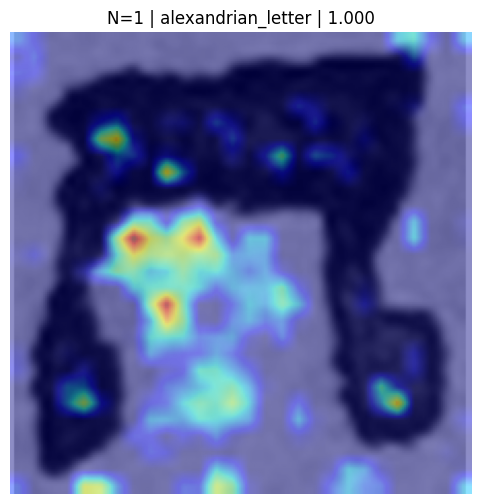

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Активирован фильтр 11 (не интерпретируемый)
- Отличительный визуальный признак: наличие круга
  Фильтр 25, вклад=1.8360, активация=0.7923
- Отличительный визуальный признак: тонкие линии
  Фильтр 49, вклад=1.8003, активация=0.6868


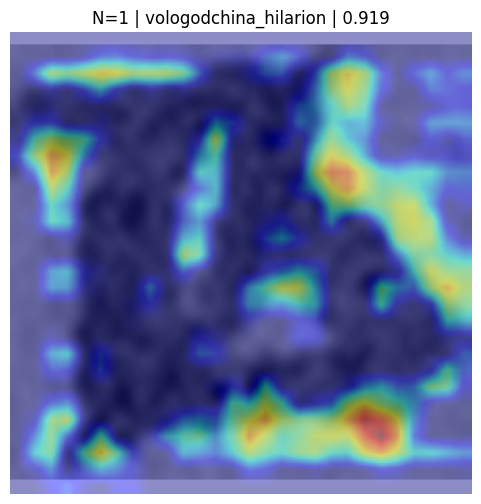

Класс: vologodchina_hilarion
Вероятность: 0.9190
Аргументация:
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 19, вклад=0.7905, активация=0.4478
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 29, вклад=0.6322, активация=0.3100
- Отличительный визуальный признак: символ похож на букву 'Ъ'
  Фильтр 16, вклад=0.6289, активация=0.3060


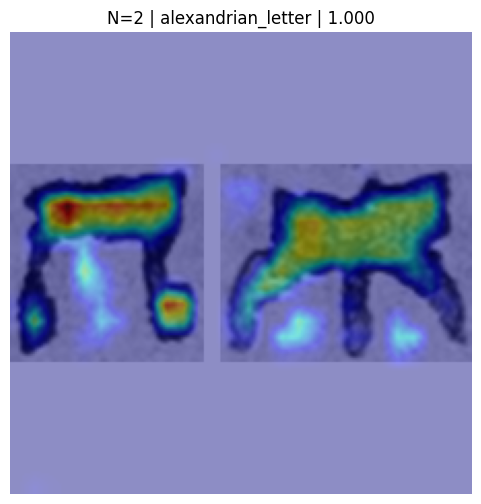

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: наличие круга
  Фильтр 26, вклад=0.3372, активация=0.4028
- Отличительный визуальный признак: наличие круга
  Фильтр 11, вклад=0.3085, активация=0.8095
- Отличительный визуальный признак: наличие круга
  Фильтр 29, вклад=0.2616, активация=0.3059


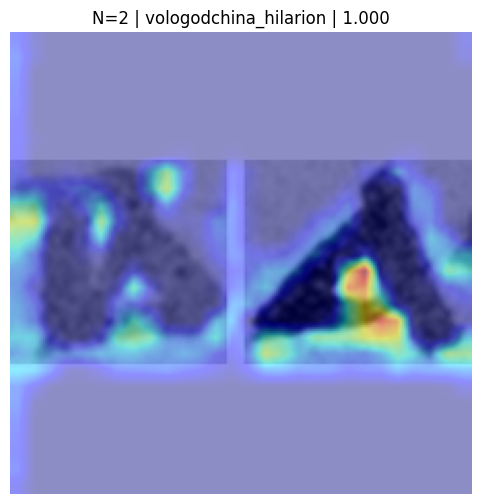

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: длинная горизонтальная линия
  Фильтр 61, вклад=5.7698, активация=1.0120
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 4, вклад=2.8363, активация=0.5495
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 48, вклад=2.6229, активация=0.3097


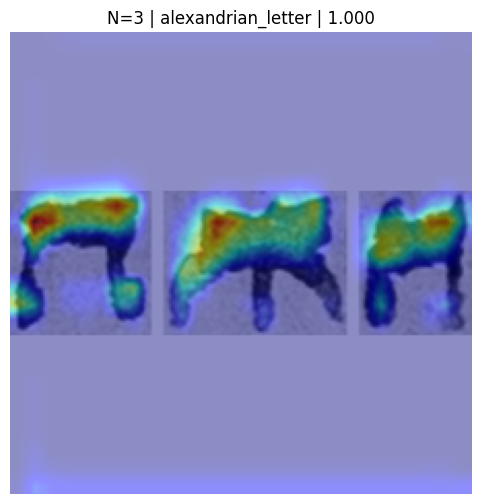

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Активирован фильтр 51 (не интерпретируемый)
- Активирован фильтр 19 (не интерпретируемый)
- Отличительный визуальный признак: пустой правый символ(ошибка при создании датасета)
  Фильтр 53, вклад=1.8071, активация=0.4187


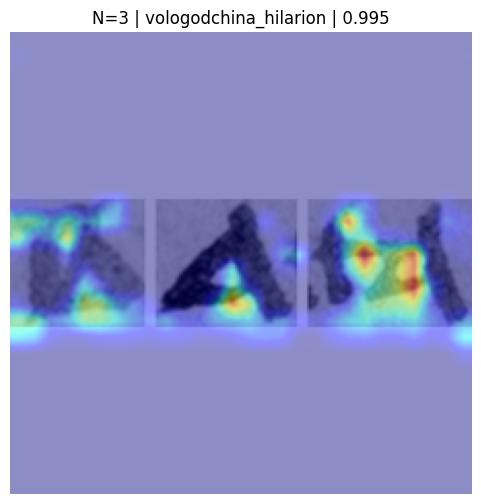

Класс: vologodchina_hilarion
Вероятность: 0.9946
Аргументация:
- Отличительный визуальный признак: длинная горизонтальная линия
  Фильтр 61, вклад=1.4683, активация=0.9985
- Отличительный визуальный признак: некоторые символы похожи на букву 'Е' или отзеркаленную '9'
  Фильтр 17, вклад=1.3273, активация=0.3119
- Отличительный визуальный признак: кучковатые штрики как у букв 'Х' или 'Ж'
  Фильтр 49, вклад=1.2746, активация=0.6056


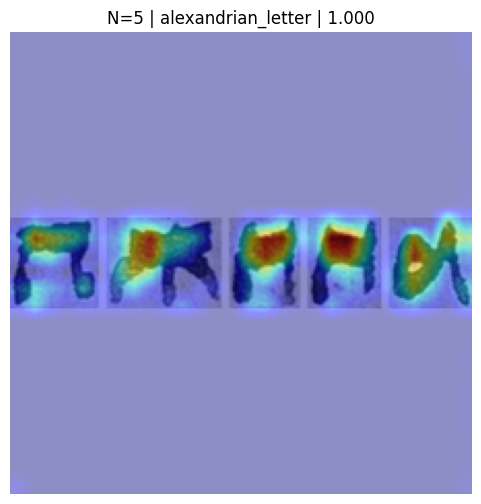

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи на букву 'о'
  Фильтр 33, вклад=1.0034, активация=0.1440
- Активирован фильтр 0 (не интерпретируемый)
- Активирован фильтр 52 (не интерпретируемый)


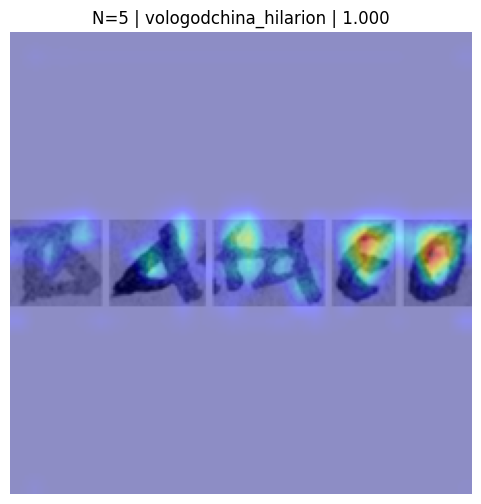

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 60, вклад=1.1830, активация=0.6905
- Отличительный визуальный признак: кучковатые штрики как у букв 'Х' или 'Ж'
  Фильтр 21, вклад=0.8230, активация=0.7286
- Отличительный визуальный признак: некоторые символы похожи на буквы 'И' или 'Н'
  Фильтр 50, вклад=0.7415, активация=1.0326


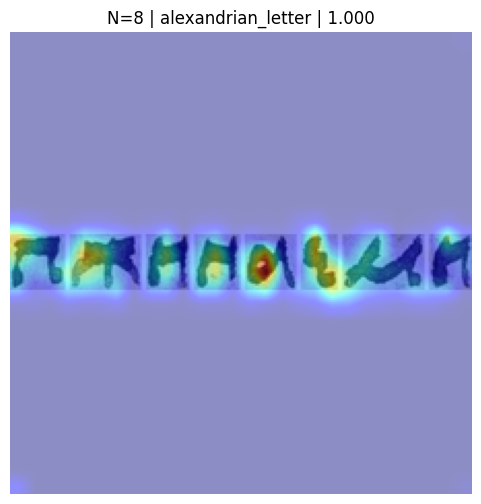

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи на перевернутую букву 'Ш'
  Фильтр 40, вклад=2.6784, активация=0.4010
- Активирован фильтр 26 (не интерпретируемый)
- Отличительный визуальный признак: некоторые символы похожи на букву 'Ъ'
  Фильтр 63, вклад=1.0790, активация=0.8800


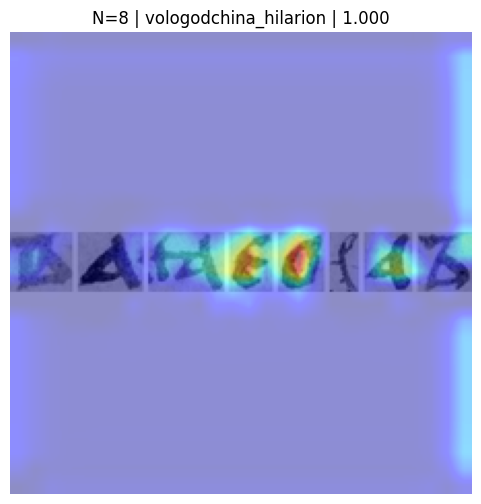

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: кучковатые штрики как у букв 'Х' или 'Ж'
  Фильтр 60, вклад=1.5440, активация=0.5815
- Активирован фильтр 51 (не интерпретируемый)
- Активирован фильтр 21 (не интерпретируемый)


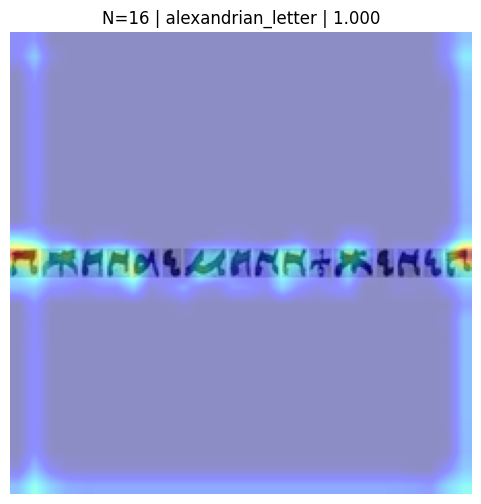

Класс: alexandrian_letter
Вероятность: 1.0000
Аргументация:
- Активирован фильтр 19 (не интерпретируемый)
- Активирован фильтр 10 (не интерпретируемый)
- Активирован фильтр 11 (не интерпретируемый)


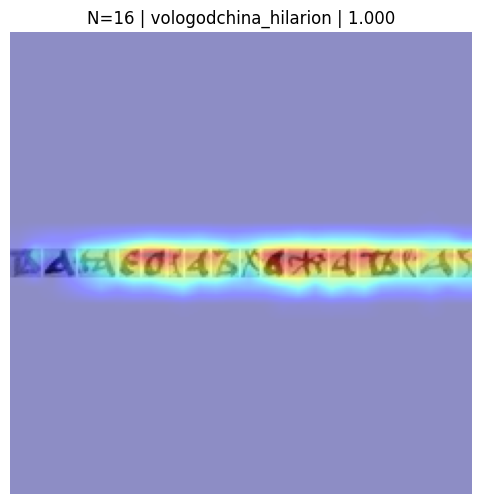

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи на перевернутую букву 'Ш'
  Фильтр 39, вклад=0.9009, активация=0.6767
- Активирован фильтр 40 (не интерпретируемый)
- Активирован фильтр 20 (не интерпретируемый)


In [ ]:
class GradCAM:
    def __init__(self,model,layer):
        self.model=model; self.layer=layer; self.a=None; self.g=None
        self.h1=layer.register_forward_hook(lambda m,i,o:setattr(self,"a",o))
        self.h2=layer.register_full_backward_hook(lambda m,gi,go:setattr(self,"g",go[0]))
    def __call__(self,x,class_id):
        self.model.zero_grad(set_to_none=True)
        z=self.model(x); z[:,class_id].sum().backward()
        w=self.g.mean((2,3),keepdim=True)
        cam=torch.relu((w*self.a).sum(1,keepdim=True))
        cam=torch.nn.functional.interpolate(cam,size=x.shape[-2:],mode="bilinear",align_corners=False)
        cam=cam[0,0].detach().cpu().numpy()
        return (cam-cam.min())/(cam.max()-cam.min()+1e-8)
    def close(self): self.h1.remove(); self.h2.remove()

def show_explanation(ex):
    n = ex["context_size"]
    model = get_model(n)
    x = preprocess(ex["path"])
    cid = CLASS_TO_ID[ex["predicted_class"]]
    g = GradCAM(model, model.layer2)         
    cam = g(x, cid); g.close()
    im = Image.open(ex["path"]).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    plt.figure(figsize=(6, 6)); plt.imshow(im, cmap="gray"); plt.imshow(cam, alpha=.45, cmap="jet")
    plt.axis("off"); plt.title(f"N={n} | {ex['predicted_class']} | {ex['confidence']:.3f}"); plt.show()
    print(ex["text"])

# для примеров по обоим классам:
for n, by_class in examples_by_class.items():
    for label, ex in by_class.items():
        show_explanation(ex)

## 14. Метрики текстовой аргументации

Здесь считаются:

- **coverage** — доля тестовых решений, где хотя бы один из top-k фильтров имеет текстовое описание;
- **mean described filters** — среднее число описанных фильтров среди top-k;
- повторяемость текстовых признаков по классу.

Эти показатели описывают устойчивость словарной аргументации, а не «истинность» археографического признака.

In [ ]:
def argumentation_metrics(n, max_samples=None):
    meta = context_metadata[n]
    meta = meta[meta.split == "test"] 
    if max_samples:
        meta = meta.sample(min(max_samples, len(meta)), random_state=SEED)
    rows = []
    for _, row in meta.iterrows():
        ex = explain_prediction(n, row.path)
        desc = [q["description"] for q in ex["top_filters"] if q["description"]]
        rows.append({"path": row.path, "true_class": row.label,
                     "predicted_class": ex["predicted_class"],
                     "correct": int(row.label == ex["predicted_class"]),
                     "num_described": len(desc), "coverage": int(bool(desc)),
                     "features": " | ".join(desc)})
    d = pd.DataFrame(rows)
    return {"context_size": n,
            "argumentation_coverage": d.coverage.mean() if len(d) else np.nan,
            "mean_described_filters": d.num_described.mean() if len(d) else np.nan,
            "argumentation_samples": len(d)}, d

arg_rows = []; argumentation_details = {}
for n in RUN_CONTEXT_SIZES:                              
    print("N=", n)
    m, d = argumentation_metrics(n, ARGUMENTATION_TEST_SAMPLES)
    arg_rows.append(m); argumentation_details[n] = d

argumentation_results = pd.DataFrame(arg_rows)
final_results = classification_results.merge(argumentation_results, on="context_size", how="left")
display(final_results)
final_results.to_csv(OUTPUT_DIR/"final_experiment_results.csv", index=False)

1
2
3
5
8
16


,context_size,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,roc_auc,test_loss,argumentation_coverage,mean_described_filters,argumentation_samples
0,2,1.000000,1.000000,1.000000,1.000000,1.000000,0.000192,1.0,0.000192,1.000000,2.999606,17777
1,3,0.999883,0.999897,0.999863,0.999897,0.999880,0.000248,1.0,0.000248,0.998356,2.142295,17028
2,5,0.999936,0.999944,0.999924,0.999944,0.999934,0.000089,1.0,0.000089,0.997553,2.412621,15530
3,8,1.000000,1.000000,1.000000,1.000000,1.000000,0.000002,1.0,0.000002,1.000000,1.883084,13283
4,16,1.000000,1.000000,1.000000,1.000000,1.000000,0.000001,1.0,0.000001,0.666895,0.681003,7301


In [ ]:
rows = []
for n in RUN_CONTEXT_SIZES:
    ckpt_path = CKPT_DIR / f"resnet18_context_{n}.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    rows.append({"context_size": ckpt["context_size"], **ckpt["metrics"]})
    del ckpt

classification_results = pd.DataFrame(rows).sort_values("context_size").reset_index(drop=True)
display(classification_results)
classification_results.to_csv(OUTPUT_DIR/"classification_results.csv", index=False)

,context_size,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,roc_auc,test_loss
0,1,0.999514,0.999513,0.999498,0.999513,0.999506,0.001793,0.999996,0.001793
1,2,1.000000,1.000000,1.000000,1.000000,1.000000,0.000192,1.000000,0.000192
2,3,0.999883,0.999897,0.999863,0.999897,0.999880,0.000248,1.000000,0.000248
3,5,0.999936,0.999944,0.999924,0.999944,0.999934,0.000089,1.000000,0.000089
4,8,1.000000,1.000000,1.000000,1.000000,1.000000,0.000002,1.000000,0.000002
5,16,1.000000,1.000000,1.000000,1.000000,1.000000,0.000001,1.000000,0.000001


In [164]:
argumentation_results = pd.DataFrame(arg_rows)
final_results = classification_results.merge(argumentation_results, on="context_size", how="left")
display(final_results)
final_results.to_csv(OUTPUT_DIR/"final_experiment_results.csv", index=False)

,context_size,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,roc_auc,test_loss,argumentation_coverage,mean_described_filters,argumentation_samples
0,1,0.999514,0.999513,0.999498,0.999513,0.999506,0.001793,0.999996,0.001793,1.000000,2.382058,18526
1,2,1.000000,1.000000,1.000000,1.000000,1.000000,0.000192,1.000000,0.000192,1.000000,2.999606,17777
2,3,0.999883,0.999897,0.999863,0.999897,0.999880,0.000248,1.000000,0.000248,0.998356,2.142295,17028
3,5,0.999936,0.999944,0.999924,0.999944,0.999934,0.000089,1.000000,0.000089,0.997553,2.412621,15530
4,8,1.000000,1.000000,1.000000,1.000000,1.000000,0.000002,1.000000,0.000002,1.000000,1.883084,13283
5,16,1.000000,1.000000,1.000000,1.000000,1.000000,0.000001,1.000000,0.000001,0.666895,0.681003,7301


## 14.1. Достоверность аргументации (абляция фильтров)

In [ ]:
def prob_after_ablation(model, x, class_id, filter_ids):
    def hook(m, i, o):
        o = o.clone(); o[:, filter_ids] = 0; return o
    h = model.layer1.register_forward_hook(hook)
    with torch.no_grad():
        p = torch.softmax(model.eval()(x), 1)[0, class_id].item()
    h.remove(); return p

def ablation_test(n, max_samples=500):
    model = get_model(n)   
    meta = context_metadata[n]
    meta = meta[meta.split == "test"]     
    meta = meta.sample(min(max_samples, len(meta)), random_state=SEED)
    rng = np.random.default_rng(SEED); rows = []
    for _, row in meta.iterrows():
        ex = explain_prediction(n, row.path)
        ids = [q["filter_id"] for q in ex["top_filters"]]
        if not ids: continue       
        x = preprocess(row.path); cid = CLASS_TO_ID[ex["predicted_class"]]
        base = ex["confidence"]
        named = prob_after_ablation(model, x, cid, ids)
        rand_ids = rng.choice(64, size=len(ids), replace=False).tolist()
        rand = prob_after_ablation(model, x, cid, rand_ids)
        rows.append({"drop_named": base - named, "drop_random": base - rand})
    d = pd.DataFrame(rows)
    return {"context_size": n,
            "drop_named": d.drop_named.mean(),
            "drop_random": d.drop_random.mean(), "samples": len(d)}

ablation_results = pd.DataFrame([ablation_test(n) for n in RUN_CONTEXT_SIZES])
display(ablation_results)

final_results = final_results.merge(ablation_results, on="context_size", how="left")
final_results.to_csv(OUTPUT_DIR/"final_experiment_results.csv", index=False)
display(final_results)

,context_size,drop_named,drop_random,samples
0,1,0.010426,-3.455311e-04,500
1,2,0.555536,1.590390e-02,500
2,3,0.002938,8.203864e-06,500
3,5,0.004295,2.599311e-05,500
4,8,0.019314,5.415440e-06,500
5,16,0.001500,6.327629e-07,500


,context_size,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,log_loss,roc_auc,test_loss,argumentation_coverage,mean_described_filters,argumentation_samples,drop_named,drop_random,samples
0,1,0.999514,0.999513,0.999498,0.999513,0.999506,0.001793,0.999996,0.001793,1.000000,2.382058,18526,0.010426,-3.455311e-04,500
1,2,1.000000,1.000000,1.000000,1.000000,1.000000,0.000192,1.000000,0.000192,1.000000,2.999606,17777,0.555536,1.590390e-02,500
2,3,0.999883,0.999897,0.999863,0.999897,0.999880,0.000248,1.000000,0.000248,0.998356,2.142295,17028,0.002938,8.203864e-06,500
3,5,0.999936,0.999944,0.999924,0.999944,0.999934,0.000089,1.000000,0.000089,0.997553,2.412621,15530,0.004295,2.599311e-05,500
4,8,1.000000,1.000000,1.000000,1.000000,1.000000,0.000002,1.000000,0.000002,1.000000,1.883084,13283,0.019314,5.415440e-06,500
5,16,1.000000,1.000000,1.000000,1.000000,1.000000,0.000001,1.000000,0.000001,0.666895,0.681003,7301,0.001500,6.327629e-07,500


## 15. Стабильность словаря между N

Нельзя считать Jaccard по номерам фильтров: фильтр 60 в одной независимо обученной модели не обязан соответствовать фильтру 60 в другой.

Поэтому сравниваем **текстовые описания признаков**.

In [167]:
def feature_sets(d):
    out={}
    for n,classes in d.items():
        s=set()
        for fs in classes.values():
            for info in fs.values():
                if info.get("description"):
                    s.add(info["description"].strip().lower())
        out[int(n)]=s
    return out

def jaccard(a,b):
    return len(a&b)/max(1,len(a|b))

fs=feature_sets(filter_dictionary); ns=sorted(fs)
stab=[]
for a,b in zip(ns[:-1],ns[1:]):
    stab.append({"context_1":a,"context_2":b,"feature_jaccard":jaccard(fs[a],fs[b])})
dictionary_stability=pd.DataFrame(stab)
display(dictionary_stability)
dictionary_stability.to_csv(OUTPUT_DIR/"dictionary_stability.csv",index=False)

,context_1,context_2,feature_jaccard
0,1,2,0.125000
1,2,3,0.272727
2,3,5,0.272727
3,5,8,0.444444
4,8,16,0.500000


In [168]:
# Сохраняем конфигурацию, чтобы эксперимент можно было воспроизвести

config={
    "context_sizes":RUN_CONTEXT_SIZES,
    "max_images_per_class":MAX_IMAGES_PER_CLASS,
    "split":[TRAIN_RATIO,VAL_RATIO,TEST_RATIO],
    "seed":SEED,"batch_size":BATCH_SIZE,"epochs":EPOCHS,"lr":LR,
    "image_size":IMAGE_SIZE,"target_symbol_height":TARGET_SYMBOL_HEIGHT,
    "symbol_gap":SYMBOL_GAP,"top_filters_per_class":TOP_FILTERS_PER_CLASS,
    "top_filters_per_image":TOP_FILTERS_PER_IMAGE
}
with open(OUTPUT_DIR/"experiment_config.json","w",encoding="utf-8") as f:
    json.dump(config,f,ensure_ascii=False,indent=2)

print("Готово. Все результаты:",OUTPUT_DIR)

Готово. Все результаты: /kaggle/working/symbol_context_experiment


Класс: vologodchina_hilarion
Вероятность: 0.9938
Аргументация:
- Отличительный визуальный признак: длинный символ в длину или в ширину, наличие прямой или чуть закругленной линии
  Фильтр 61, вклад=0.7352, активация=0.9359
- Отличительный визуальный признак: прямые горизонтальная и вертикальная линии
  Фильтр 17, вклад=0.6779, активация=0.5815
- Отличительный визуальный признак: прямые горизонтальная и вертикальная линии
  Фильтр 57, вклад=0.5691, активация=0.4700


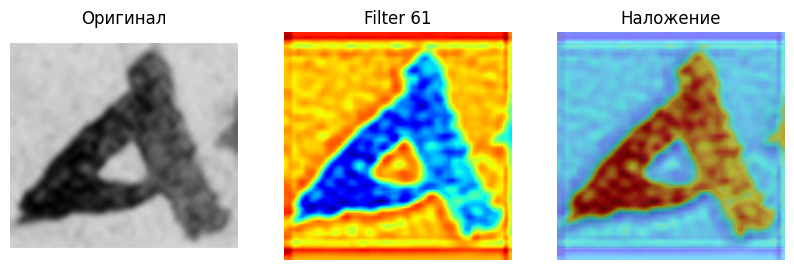

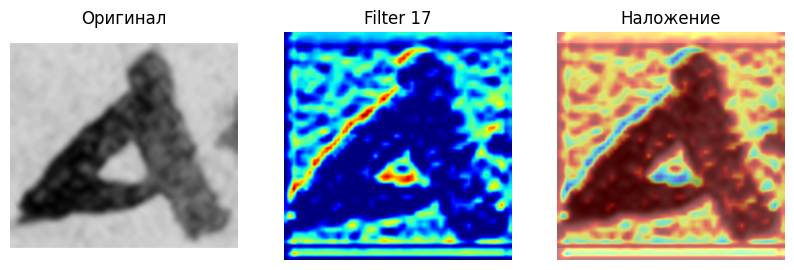

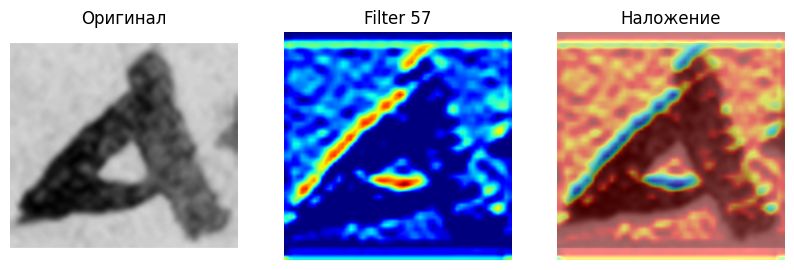


Grad-CAM:


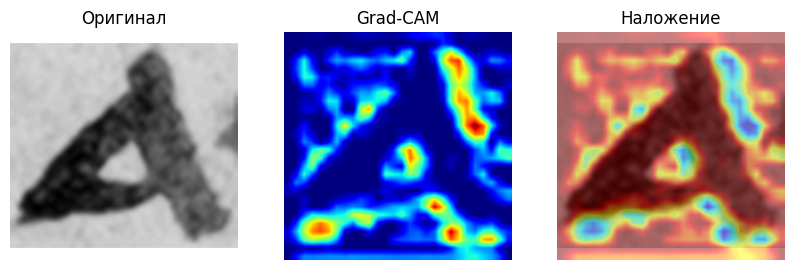

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: длинная горизонтальная линия
  Фильтр 61, вклад=5.0417, активация=0.9258
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 4, вклад=3.4133, активация=0.5993
- Отличительный визуальный признак: один из символов похож на букву 'Е'
  Фильтр 21, вклад=3.3630, активация=0.7224


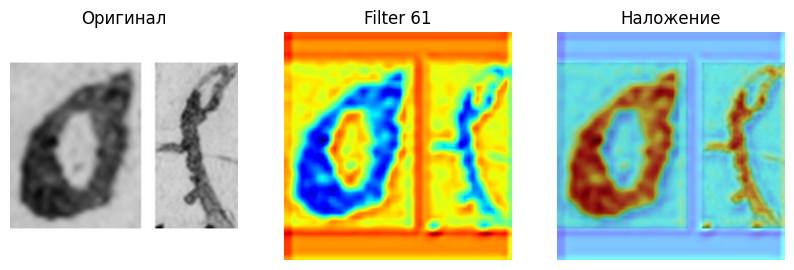

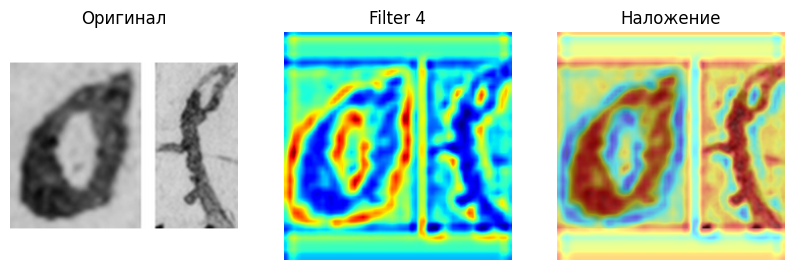

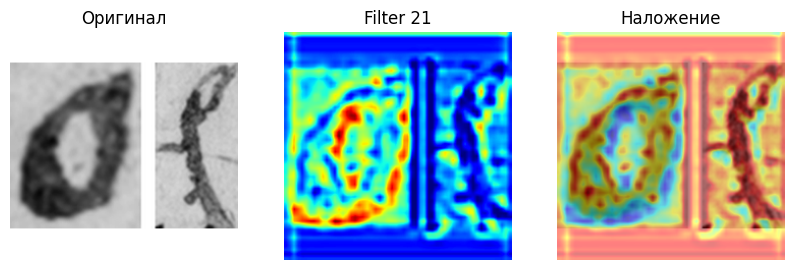


Grad-CAM:


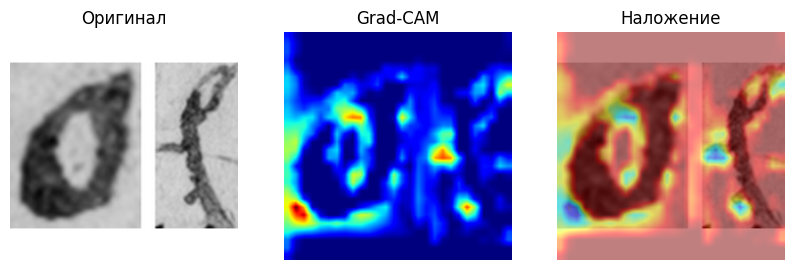

Класс: vologodchina_hilarion
Вероятность: 0.9880
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи на букву 'Е' или отзеркаленную '9'
  Фильтр 17, вклад=1.8777, активация=0.4257
- Отличительный визуальный признак: длинная горизонтальная линия
  Фильтр 61, вклад=1.3515, активация=0.9530
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 38, вклад=1.2948, активация=0.7471


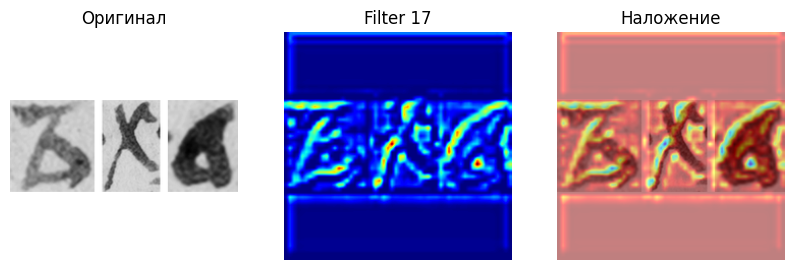

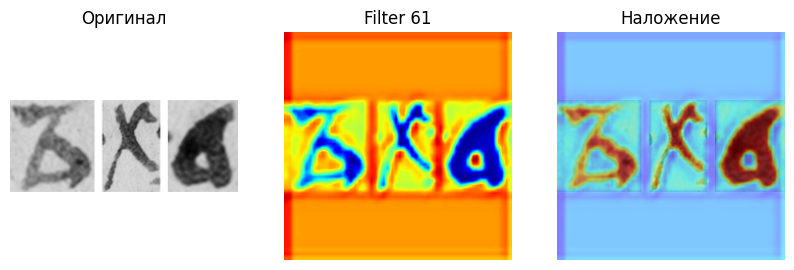

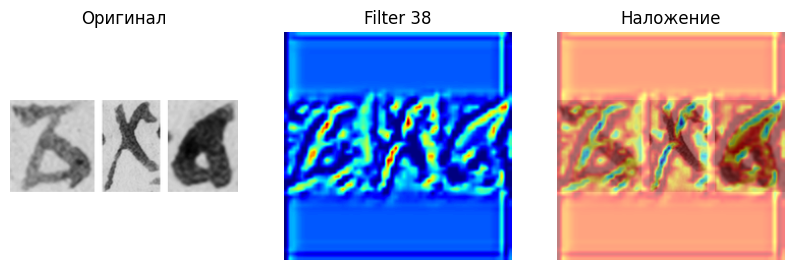


Grad-CAM:


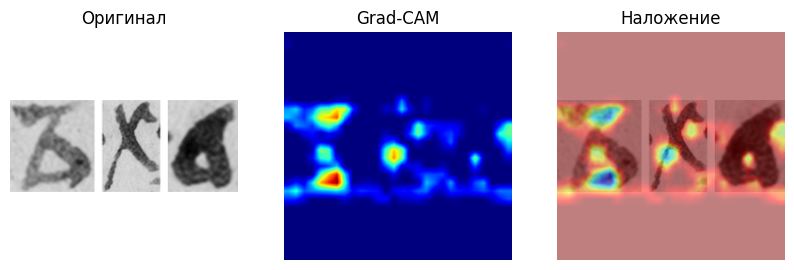

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: несколько символов в одном изображении(ошибка при создании датасета)
  Фильтр 60, вклад=1.1468, активация=0.6693
- Отличительный визуальный признак: кучковатые штрики как у букв 'Х' или 'Ж'
  Фильтр 21, вклад=0.8407, активация=0.7321
- Отличительный визуальный признак: некоторые символы похожи на буквы 'И' или 'Н'
  Фильтр 51, вклад=0.5346, активация=0.6298


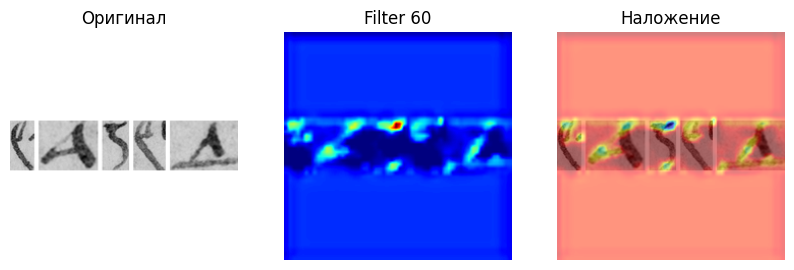

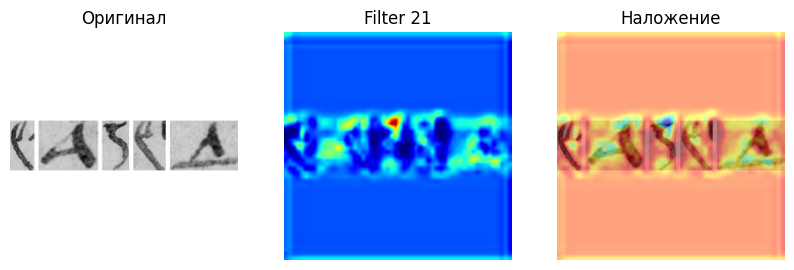

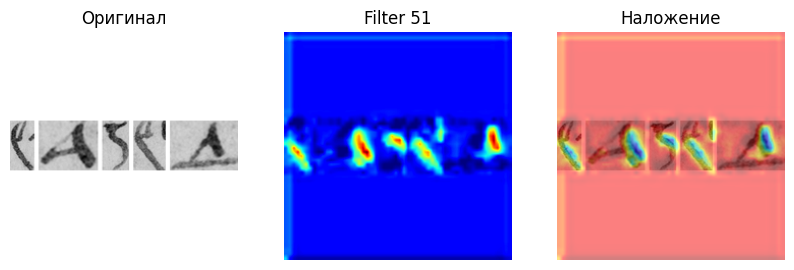


Grad-CAM:


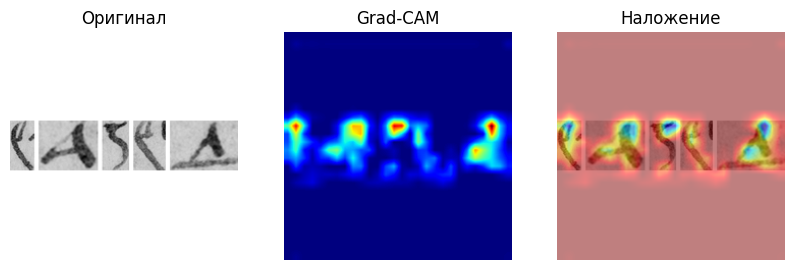

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Активирован фильтр 51 (не интерпретируемый)
- Отличительный визуальный признак: кучковатые штрики как у букв 'Х' или 'Ж'
  Фильтр 60, вклад=0.9082, активация=0.6113
- Отличительный визуальный признак: некоторые символы похожи на буквы 'И' или 'Н'
  Фильтр 50, вклад=0.4787, активация=1.0388


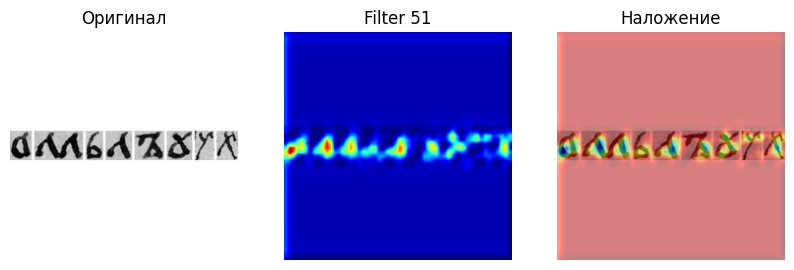

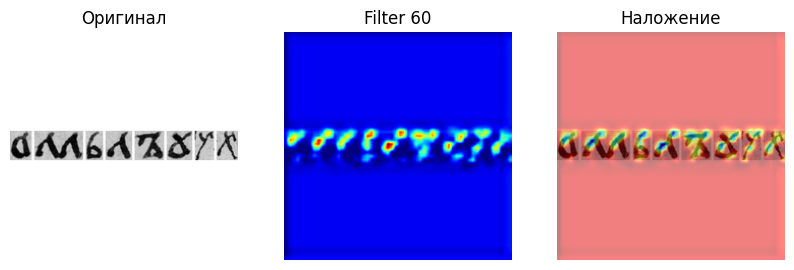

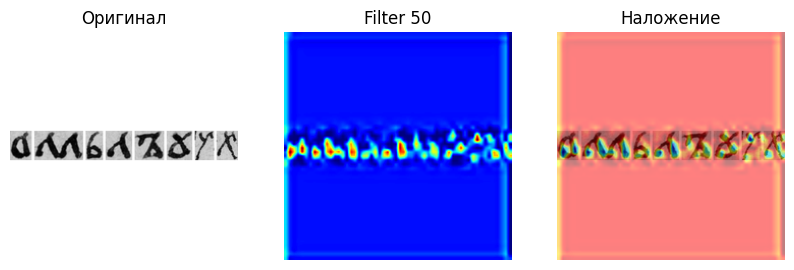


Grad-CAM:


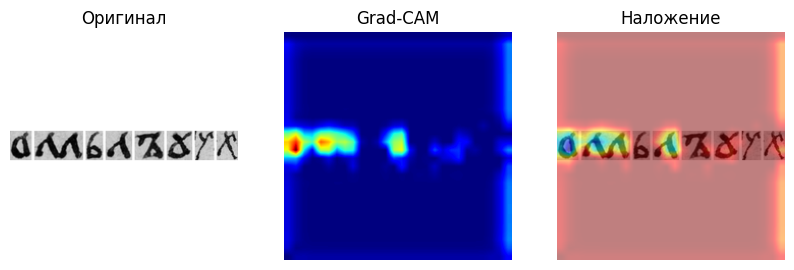

Класс: vologodchina_hilarion
Вероятность: 1.0000
Аргументация:
- Отличительный визуальный признак: некоторые символы похожи на перевернутую букву 'Ш'
  Фильтр 39, вклад=0.9658, активация=0.6969
- Активирован фильтр 40 (не интерпретируемый)
- Активирован фильтр 20 (не интерпретируемый)


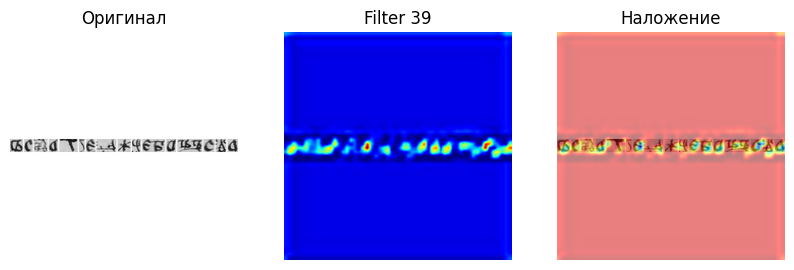

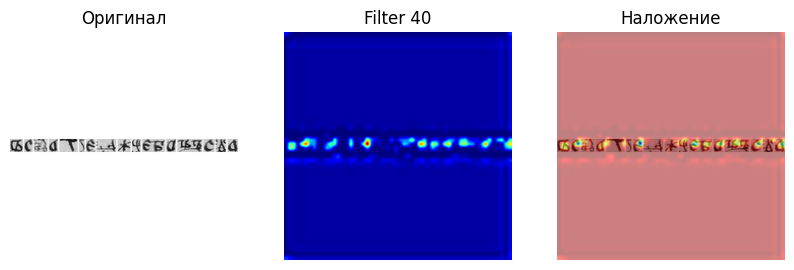

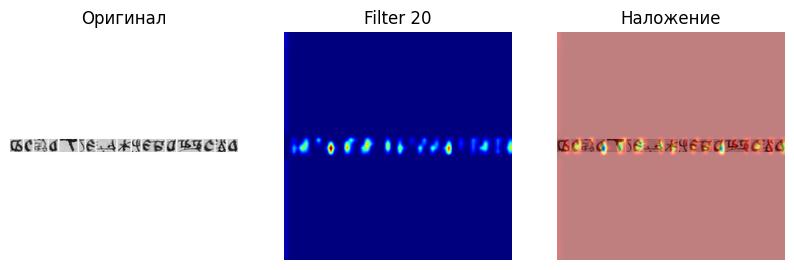


Grad-CAM:


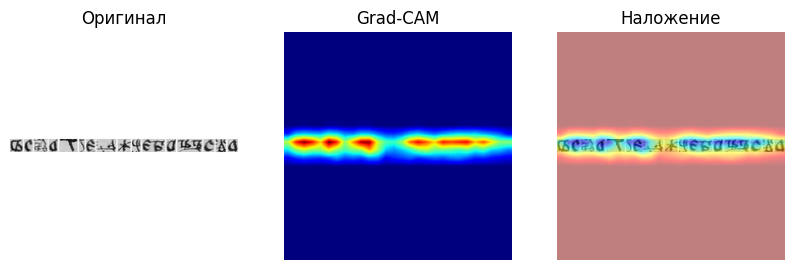

In [172]:
import cv2
import matplotlib.pyplot as plt

class GradCAM:
    def __init__(self, model, layer):
        self.model = model; self.layer = layer; self.a = None; self.g = None
        self.h1 = layer.register_forward_hook(lambda m, i, o: setattr(self, "a", o))
        self.h2 = layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "g", go[0]))
    def __call__(self, x, class_id):
        self.model.zero_grad(set_to_none=True)
        z = self.model(x); z[:, class_id].sum().backward()
        w = self.g.mean((2, 3), keepdim=True)
        cam = torch.relu((w * self.a).sum(1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    def close(self): self.h1.remove(); self.h2.remove()

def visualize_filter_importance(n, path, filter_id, class_id=None):
    """
    Рисует панель 'Оригинал / Filter N (вклад) / Наложение'
    для одного фильтра слоя layer1 на конкретном изображении.
    """
    model = get_model(n)
    x = preprocess(path)
    x.requires_grad_(False)

    cid_tensor = None if class_id is None else torch.tensor([class_id], device=DEVICE)
    p, cid, act, contrib = layer1_scores(model, x, cid_tensor)

    # достаём пространственную карту активации фильтра filter_id напрямую
    store = {}
    h = model.layer1.register_forward_hook(lambda m, i, o: store.__setitem__("a", o.detach()))
    with torch.no_grad():
        model(x)
    h.remove()
    fmap = store["a"][0, filter_id].cpu().numpy()   # [H,W] активация конкретного фильтра

    fmap = fmap - fmap.min()
    fmap = fmap / (fmap.max() + 1e-8)
    fmap_resized = cv2.resize(fmap, (IMAGE_SIZE, IMAGE_SIZE))

    img_np = x[0, 0].detach().cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    heatmap = cv2.applyColorMap(np.uint8(255 * fmap_resized), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    img_rgb = np.stack([img_np] * 3, axis=-1)

    overlay = heatmap * 0.5 + img_rgb * 0.5
    overlay = (overlay - overlay.min()) / (overlay.max() - overlay.min() + 1e-8)

    contrib_val = float(contrib[0, filter_id])

    plt.figure(figsize=(10, 3))
    plt.subplot(1, 3, 1); plt.title("Оригинал")
    plt.imshow(img_np, cmap="gray"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.title(f"Filter {filter_id}")
    plt.imshow(fmap_resized, cmap="jet"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.title("Наложение")
    plt.imshow(overlay); plt.axis("off")
    plt.show()

def visualize_gradcam(n, path, class_id=None):
    """
    Рисует панель 'Оригинал / Grad-CAM / Наложение' по слою layer1
    для итоговой карты значимых областей изображения.
    """
    model = get_model(n)
    x = preprocess(path)
    cid = CLASS_TO_ID[class_id] if isinstance(class_id, str) else class_id
    if cid is None:
        with torch.no_grad():
            cid = int(model(x).argmax(1)[0])

    g = GradCAM(model, model.layer2)
    cam = g(x, cid); g.close()
    cam_resized = cv2.resize(cam, (IMAGE_SIZE, IMAGE_SIZE))

    img_np = x[0, 0].detach().cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)

    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    img_rgb = np.stack([img_np] * 3, axis=-1)

    overlay = heatmap * 0.5 + img_rgb * 0.5
    overlay = (overlay - overlay.min()) / (overlay.max() - overlay.min() + 1e-8)

    plt.figure(figsize=(10, 3))
    plt.subplot(1, 3, 1); plt.title("Оригинал")
    plt.imshow(img_np, cmap="gray"); plt.axis("off")
    plt.subplot(1, 3, 2); plt.title("Grad-CAM")
    plt.imshow(cam_resized, cmap="jet"); plt.axis("off")
    plt.subplot(1, 3, 3); plt.title("Наложение")
    plt.imshow(overlay); plt.axis("off")
    plt.show()

def show_top_filters(ex, k=3):
    """Рисует панели для k фильтров (по вкладу, contribution > 0), затем Grad-CAM."""
    n = ex["context_size"]
    print(ex["text"])
    for q in ex["top_filters"][:k]:
        visualize_filter_importance(n, ex["path"], q["filter_id"])
    print("\nGrad-CAM:")
    visualize_gradcam(n, ex["path"], class_id=CLASS_TO_ID[ex["predicted_class"]])

# пример использования:
for ex in examples.values():
    show_top_filters(ex)

# Полная инструкция


### 1. Данные
Загрузите изображения **строк** с HF или с диска в две папки:

```text
dataset/
  alexandrian_letter/
  vologodchina_hilarion/
```

Изображения уже нарезанных символов сюда не нужны.

### 2. Пути
Измените `SOURCE_DIRS` в первой ячейке.

### 3. Проверка сегментации
Сначала поставьте:

```python
RUN_CONTEXT_SIZES = [1]
```

Выполните ячейки до визуализации сегментации. Проверьте рамки на 20–30 строках.

Если сегментация плохая, меняйте:

```python
MIN_COMPONENT_AREA
MIN_COMPONENT_HEIGHT
MIN_COMPONENT_WIDTH
```

и повторяйте проверку.

### 4. Основной запуск
Верните:

```python
RUN_CONTEXT_SIZES = [1,2,3,5,8,16]
```

и запустите обучение.

### 5. Заполнение словаря
После обучения откройте:

```text
symbol_context_experiment/filter_galleries/
```

Для каждого `context_N`, класса и `filter_XX` просмотрите 9 изображений максимальной активации.

Потом откройте:

```text
filter_dictionaries.json
```

и заполните:

```json
"description": "текстовое описание признака"
```

Если фильтр не имеет устойчивой интерпретации:

```json
"description": null
```

**Это единственный обязательный ручной этап.** Именно здесь реализуется научная часть интерпретации, как в предыдущей работе.

### 6. Продолжение после словаря
После сохранения JSON выполните ячейки начиная с раздела **«Текстовая аргументация конкретного решения»**.

Обучать модели заново не надо.

### 7. Что получится
Для каждого тестового изображения система выдаёт:

```text
Класс: ...
Вероятность: ...
Аргументация:
- Отличительный визуальный признак: ...
- Фильтр ...: ...
- Активирован фильтр ... (не интерпретируемый)
```

и отдельно Grad-CAM.

### 8. Главные файлы результатов

```text
classification_results.csv
final_experiment_results.csv
dictionary_stability.csv
filter_dictionaries.json
experiment_config.json
resnet18_context_N.pt
```